# Teste geográfico: como provar que a mídia traz resultado

```

Teste geográfico: como provar que a mídia traz resultado

Pergunta: se a Loft colocar mais verba numa cidade e os anúncios subirem, como saber
se o aumento veio da mídia ou teria acontecido de qualquer jeito?

Ideia: a Loft coloca mais verba em algumas cidades e mantém a verba igual em
CIDADES DE COMPARAÇÃO, parecidas com elas. O que as cidades de comparação fizeram
mostra O QUE TERIA ACONTECIDO SEM A MÍDIA. O efeito da mídia é a diferença entre o
que a cidade com mais verba fez e o que as cidades de comparação indicavam.
Tudo depende de as cidades de comparação serem BOAS: quando nada muda, elas
precisam acompanhar bem a cidade.

Machine learning usado:
  1. PCA (não supervisionado): resume o perfil de cada município (variáveis públicas
     + mercado de aluguel da base Loft) em poucos componentes.
  2. KNN - vizinhos mais próximos (não supervisionado): para cada cidade, acha as
     cidades mais parecidas = cidades de comparação.
  3. Controle sintético (regressão com pesos não negativos): dá um peso diferente a
     cada cidade de comparação.
  4. Ridge supervisionado: aprende, com todas as cidades e momentos do passado, a
     prever a variação de uma cidade a partir das cidades de comparação, do Brasil
     e do próprio histórico.

Validação - ENSAIO NO PASSADO:
  Em vários momentos do passado, em que ninguém mexeu na verba, finge que cada cidade
  recebeu mais verba e usa as cidades de comparação para prever os 3 meses seguintes.
  Como nada mudou de verdade, o erro dessa previsão é a VARIAÇÃO POR ACASO.
  Quanto menor essa variação, menor o aumento que o teste consegue provar.
  Baselines: sem comparação (repete o último mês), 5 cidades sorteadas do mesmo
  cluster, 5 sorteadas da mesma UF, 5 sorteadas de qualquer lugar. Referência:
  o Brasil inteiro como comparação (inviável na prática, mas mostra o limite).

Métrica de negócio: MENOR AUMENTO QUE DÁ PARA PROVAR. Com 95% de confiança e 80% de
poder estatístico, qual o menor aumento de anúncios que o teste conseguiria provar?
O notebook usa essa métrica para desenhar o teste: quantas cidades e por quanto tempo.

Resultado medido: anúncios de aluguel residencial por mês (base Loft), como
substituto do MQL. Com os dados internos da Loft, basta trocar pela série de MQL.

Entradas:
  DATA_DIR/<base Loft>, DATA_DIR/base_municipios_POC.csv
  reports/tables/qualidade_meses_aluguel.csv (03) e 08_mercado_latente_municipios.csv (08)

Saídas:
  reports/tables/teste_geografico_comparacao_metodos.csv
  reports/tables/teste_geografico_escolha_de_k.csv
  reports/tables/teste_geografico_desenho.csv
  reports/tables/teste_geografico_balanceamento.csv
  reports/tables/teste_geografico_cidades_de_comparacao.csv
  reports/figures/teste_geografico_comparacao_metodos.png
  reports/figures/teste_geografico_exemplo.png
  reports/figures/teste_geografico_desenho.png
  reports/figures/teste_geografico_recomendado.png
```

## Imports

In [28]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from scipy.optimize import nnls
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Parâmetros

In [29]:
ARQUIVO_LOFT = "bq-results-20261005-170605-1791220258075.csv"
ARQUIVO_MUNICIPIOS = "base_municipios_POC.csv"

SEMENTE = 42
TIPO_RESIDENCIAL = "apartment_house"

MIN_ANUNCIOS_MES = 30         # cidade precisa de série estável para entrar no teste
MESES_TESTE = 3               # duração do teste simulado
MESES_SELECAO = 8             # meses iniciais usados só para escolher as cidades de comparação do ensaio
K_CANDIDATOS = [3, 5, 10]     # quantidades de cidades de comparação testadas
VARIANCIA_PCA = 0.90          # PCA guarda os componentes que explicam 90% da variação
POPULACAO_MINIMA_CANDIDATO = 100_000
TOLERANCIA_K = 0.05           # parcimônia: menor k com erro até 5% acima do melhor
META_MENOR_AUMENTO = 25       # o teste recomendado deve conseguir provar aumentos de 25% ou mais

# Menor aumento que dá para provar = (z de 95% bicaudal + z de 80% de poder) x erro do ensaio
Z_CONFIANCA, Z_PODER = 1.96, 0.84

VARIAVEIS_PUBLICAS = [
    "administradoras_10k", "imobiliarias_10k", "imobiliarias_novas_pct",
    "pix_pf_por_hab", "salario_admissao", "cadunico_pct", "credito_per_capita",
    "veiculos_por_hab", "saldo_emprego_pct", "internet_movel_100", "banda_larga_100",
    "alavancagem", "reserva_per_capita", "corretores_seguros_10k",
    "crescimento_populacional_pct", "jovens_admissoes_pct",
]

## Caminhos

In [30]:
# No notebook não existe __file__: o projeto é a pasta acima de notebooks/
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_DIR / ".env")

caminho_dados = os.getenv("DATA_DIR")
if caminho_dados is None:
    raise ValueError("A variável DATA_DIR não foi encontrada. Confira o arquivo .env.")

DATA_DIR = Path(caminho_dados)
ARQUIVO = DATA_DIR / os.getenv("LOFT_FILE", ARQUIVO_LOFT)
ARQUIVO_MUN = DATA_DIR / os.getenv("MUNICIPIOS_FILE", ARQUIVO_MUNICIPIOS)

TABLES_DIR = PROJECT_DIR / "reports" / "tables"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

ARQUIVO_QUALIDADE = TABLES_DIR / "qualidade_meses_aluguel.csv"
ARQUIVO_LATENTE = TABLES_DIR / "08_mercado_latente_municipios.csv"

for arquivo, dica in [
    (ARQUIVO, "coloque o CSV da Loft na pasta DATA_DIR"),
    (ARQUIVO_MUN, "coloque base_municipios_POC.csv na pasta DATA_DIR"),
    (ARQUIVO_QUALIDADE, "rode antes o notebook 03_potencial_mercado"),
    (ARQUIVO_LATENTE, "rode antes o notebook 08_mercado_latente"),
]:
    if not arquivo.exists():
        raise FileNotFoundError(f"{arquivo.name} não encontrado: {dica}.")

## Série mensal de anúncios por cidade (base loft)

In [31]:
qualidade = pd.read_csv(ARQUIVO_QUALIDADE, parse_dates=["mes"])
meses = sorted(qualidade.loc[qualidade["status"] == "válido", "mes"])
T = len(meses)

loft = pd.read_csv(
    ARQUIVO,
    usecols=["snapshot_month", "normalized_state_seed", "normalized_city_seed",
             "operation_type", "property_type_group", "n_listings"],
    dtype={"normalized_state_seed": str, "normalized_city_seed": str,
           "operation_type": str, "property_type_group": str},
    parse_dates=["snapshot_month"],
)
loft = loft[
    loft["snapshot_month"].isin(meses)
    & (loft["operation_type"] == "rent")
    & (loft["property_type_group"] == TIPO_RESIDENCIAL)
]

serie = (
    loft.groupby(["normalized_state_seed", "normalized_city_seed", "snapshot_month"])["n_listings"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=meses, fill_value=0)
)
serie_brasil = serie.sum(axis=0)

# Só cidades com anúncio em todos os meses e volume suficiente para uma série estável
estavel = (serie > 0).all(axis=1) & (serie.mean(axis=1) >= MIN_ANUNCIOS_MES)
serie = serie[estavel].reset_index().rename(
    columns={"normalized_state_seed": "sigla_uf", "normalized_city_seed": "cidade"}
)

print(f"Meses válidos na série: {T} ({meses[0]:%Y-%m} a {meses[-1]:%Y-%m})")
print("Observação: fev e mar/2026 foram descartados no 03, então há um salto nesse ponto da série.")
print(f"Cidades com série estável (anúncio todo mês e {MIN_ANUNCIOS_MES}+ por mês):", len(serie))

Meses válidos na série: 20 (2024-11 a 2026-08)
Observação: fev e mar/2026 foram descartados no 03, então há um salto nesse ponto da série.
Cidades com série estável (anúncio todo mês e 30+ por mês): 219


## Junção com a base pública de municípios

In [32]:
def normalizar_nome(s):
    return (
        s.astype(str).str.normalize("NFKD").str.encode("ascii", errors="ignore")
        .str.decode("ascii").str.upper().str.replace(r"[^A-Z ]", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True).str.strip()
    )


municipios = pd.read_csv(ARQUIVO_MUN, dtype={"id_municipio": str})
municipios["chave"] = normalizar_nome(municipios["municipio"])
serie["chave"] = normalizar_nome(serie["cidade"])

latente = pd.read_csv(ARQUIVO_LATENTE, dtype={"id_municipio": str})[["id_municipio", "leitura"]]

base = (
    serie.merge(municipios, on=["sigla_uf", "chave"], how="inner")
    .merge(latente, on="id_municipio", how="left")
    .reset_index(drop=True)
)

# Matriz de log dos anúncios: linhas = cidades, colunas = meses
Y = np.log(base[meses].to_numpy(dtype=float))
Y_BRASIL = np.log(serie_brasil.to_numpy(dtype=float))
N = len(base)

print("Cidades com série estável e dados públicos:", N)

Cidades com série estável e dados públicos: 217


## Variáveis de perfil (para o pca e o knn)

In [33]:
def variaveis_perfil(ate_mes):
    """Perfil público + mercado de aluguel calculado SÓ com os meses até 'ate_mes'."""
    perfil = base[VARIAVEIS_PUBLICAS].copy()
    perfil["log_populacao"] = np.log(base["populacao"])
    janela = Y[:, :ate_mes]
    perfil["nivel_aluguel_per_capita"] = janela.mean(axis=1) - np.log(base["populacao"].to_numpy())
    perfil["tendencia_aluguel"] = np.polyfit(np.arange(ate_mes), janela.T, 1)[0]
    perfil["volatilidade_aluguel"] = np.diff(janela, axis=1).std(axis=1)
    for cluster in sorted(base["tipo_de_praca"].unique()):
        perfil[f"praca_{cluster}"] = (base["tipo_de_praca"] == cluster).astype(float)
    return perfil


def espaco_pca(ate_mes):
    """Padroniza, preenche faltantes pela mediana e projeta no PCA."""
    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        PCA(n_components=VARIANCIA_PCA, random_state=SEMENTE),
    )
    coordenadas = pipeline.fit_transform(variaveis_perfil(ate_mes))
    return coordenadas, pipeline[-1]

## Funções: o que teria acontecido sem a mídia

In [34]:
def previsao_sem_midia(i, serie_comparacao, origem, meses_teste=MESES_TESTE):
    """
    O que a cidade i teria feito nos meses após 'origem' sem mudança de verba:
    parte do último valor observado da cidade e segue a VARIAÇÃO da comparação.
    (As séries se comportam quase como passeio aleatório; partir do último mês é
    mais preciso que partir da média do período anterior.)
    """
    teste = slice(origem + 1, origem + 1 + meses_teste)
    return Y[i, origem] + (serie_comparacao[teste] - serie_comparacao[origem])


def erro_ensaio(i, comparacao, origem, meses_teste=MESES_TESTE):
    """Erro do ensaio no passado: real - previsão sem mídia, na média dos meses de teste."""
    teste = slice(origem + 1, origem + 1 + meses_teste)
    return (Y[i, teste] - previsao_sem_midia(i, Y[comparacao].mean(0), origem, meses_teste)).mean()


def controle_sintetico(i, vizinhos, origem):
    """Pesos não negativos, somando 1, que melhor reproduzem as variações da cidade antes da origem."""
    variacoes = np.diff(Y[:, : origem + 1], axis=1)
    pesos, _ = nnls(variacoes[vizinhos].T, variacoes[i])
    pesos = pesos / pesos.sum() if pesos.sum() > 0 else np.full(len(vizinhos), 1 / len(vizinhos))
    return pesos @ Y[vizinhos], pesos


def menor_aumento_provavel(rmse):
    """Menor aumento (%) que dá para provar com 95% de confiança e 80% de poder."""
    return np.expm1((Z_CONFIANCA + Z_PODER) * rmse) * 100

## Cidades de comparação para o ensaio no passado (escolhidas só com os primeiros meses)

In [35]:
rng = np.random.default_rng(SEMENTE)
origens = list(range(MESES_SELECAO - 1, T - MESES_TESTE))

# Para cada cidade, o KNN escolhe as cidades mais parecidas com ela. Essa escolha usa
# só os primeiros MESES_SELECAO meses, para que os meses usados no ensaio não
# influenciem quem é parecido com quem (sem vazamento)
coordenadas_ensaio, _ = espaco_pca(MESES_SELECAO)
_, comparacao_ensaio = NearestNeighbors(n_neighbors=max(K_CANDIDATOS) + 1).fit(coordenadas_ensaio).kneighbors(coordenadas_ensaio)
comparacao_ensaio = [[j for j in linha if j != i] for i, linha in enumerate(comparacao_ensaio)]

clusters = base["tipo_de_praca"].to_numpy()
ufs = base["sigla_uf"].to_numpy()
K_PADRAO = 5

print(f"Ensaio no passado: {len(origens)} momentos x {N} cidades, simulando um teste de {MESES_TESTE} meses")

Ensaio no passado: 10 momentos x 217 cidades, simulando um teste de 3 meses


## Modelo que aprende a prever o que teria acontecido sem a mídia (dados para treino)

In [36]:
# Para cada cidade e cada momento do passado: o quanto a cidade variou nos meses seguintes
# (o que o modelo deve prever) e o que já se sabia naquele momento (variáveis).
# As variações das cidades de comparação e do Brasil DURANTE o teste podem ser usadas:
# num teste real elas são observadas ao mesmo tempo.
linhas_modelo = []
for origem in range(3, T - MESES_TESTE):
    teste = slice(origem + 1, origem + 1 + MESES_TESTE)
    for i in range(N):
        comparacao = Y[comparacao_ensaio[i][:K_PADRAO]]
        linhas_modelo.append({
            "origem": origem,
            "cidade": i,
            "alvo": (Y[i, teste] - Y[i, origem]).mean(),
            "variacao_comparacao": (comparacao[:, teste] - comparacao[:, [origem]]).mean(),
            "variacao_brasil": (Y_BRASIL[teste] - Y_BRASIL[origem]).mean(),
            "variacao_propria_1m": Y[i, origem] - Y[i, origem - 1],
            "variacao_propria_3m": Y[i, origem] - Y[i, origem - 3],
            "volatilidade_propria": np.diff(Y[i, : origem + 1]).std(),
            "tamanho_log": Y[i, : origem + 1].mean(),
        })
dados_modelo = pd.DataFrame(linhas_modelo)
VARIAVEIS_MODELO = [c for c in dados_modelo.columns if c not in ("origem", "cidade", "alvo")]

## Ensaio no passado: qual forma de escolher as cidades de comparação erra menos

In [37]:
erros = {}


def registrar(nome, valor):
    erros.setdefault(nome, []).append(valor)


for origem in origens:
    teste = slice(origem + 1, origem + 1 + MESES_TESTE)

    # Modelo supervisionado treinado só com momentos cujo resultado já era conhecido
    treino_modelo = dados_modelo[dados_modelo["origem"] <= origem - MESES_TESTE]
    ridge_modelo = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 20)))
    ridge_modelo.fit(treino_modelo[VARIAVEIS_MODELO], treino_modelo["alvo"])
    agora = dados_modelo[dados_modelo["origem"] == origem].set_index("cidade")
    previsto_modelo = ridge_modelo.predict(agora[VARIAVEIS_MODELO])

    for i in range(N):
        outros = np.array([j for j in range(N) if j != i])
        mesmo_cluster = outros[clusters[outros] == clusters[i]]
        mesma_uf = outros[ufs[outros] == ufs[i]]
        if len(mesma_uf) < K_PADRAO:
            mesma_uf = outros
        parecidas = comparacao_ensaio[i]

        registrar("Baseline - sem comparação (repete o último mês)", (Y[i, teste] - Y[i, origem]).mean())
        # Baselines sorteados: UM grupo por momento, como num teste real
        registrar("Baseline - 5 cidades sorteadas (qualquer)", erro_ensaio(i, rng.choice(outros, K_PADRAO, replace=False), origem))
        registrar("Baseline - 5 cidades sorteadas (mesma UF)", erro_ensaio(i, rng.choice(mesma_uf, min(K_PADRAO, len(mesma_uf)), replace=False), origem))
        registrar("Baseline - 5 cidades sorteadas (mesmo cluster)", erro_ensaio(i, rng.choice(mesmo_cluster, min(K_PADRAO, len(mesmo_cluster)), replace=False), origem))
        registrar("KNN - 1 cidade de comparação", erro_ensaio(i, parecidas[:1], origem))
        registrar("KNN - média de 5 cidades de comparação", erro_ensaio(i, parecidas[:K_PADRAO], origem))
        sintetico, _ = controle_sintetico(i, parecidas[:K_PADRAO], origem)
        registrar("Controle sintético - 5 cidades de comparação com pesos",
                  (Y[i, teste] - previsao_sem_midia(i, sintetico, origem)).mean())
        registrar("Ridge - modelo que aprende a previsão sem mídia", agora.loc[i, "alvo"] - previsto_modelo[i])
        registrar("Referência - Brasil inteiro", (Y[i, teste] - previsao_sem_midia(i, Y_BRASIL, origem)).mean())

comparacao_metodos = pd.DataFrame([
    {"metodo": nome, "RMSE_log": np.sqrt(np.mean(np.square(v))), "vies_log": np.mean(v)}
    for nome, v in erros.items()
]).sort_values("RMSE_log")
comparacao_metodos["menor_aumento_provavel_1_cidade_pct"] = menor_aumento_provavel(comparacao_metodos["RMSE_log"])

print("\n============================")
print("COMPARAÇÃO DOS MÉTODOS (menor erro = teste mais preciso)")
print("============================")
print(comparacao_metodos.round(4).to_string(index=False))

# O que o modelo supervisionado aprendeu (coeficientes padronizados, com todos os momentos)
ridge_total = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 20)))
ridge_total.fit(dados_modelo[VARIAVEIS_MODELO], dados_modelo["alvo"])
coeficientes = pd.Series(ridge_total[-1].coef_, index=VARIAVEIS_MODELO).sort_values(key=abs, ascending=False)
print("\nCoeficientes do modelo supervisionado (variáveis padronizadas):")
print(coeficientes.round(4).to_string())


COMPARAÇÃO DOS MÉTODOS (menor erro = teste mais preciso)
                                                metodo  RMSE_log  vies_log  menor_aumento_provavel_1_cidade_pct
                KNN - média de 5 cidades de comparação    0.2308    0.0010                              90.8600
                           Referência - Brasil inteiro    0.2311   -0.0424                              90.9805
Controle sintético - 5 cidades de comparação com pesos    0.2316    0.0032                              91.2745
             Baseline - 5 cidades sorteadas (mesma UF)    0.2348   -0.0024                              92.9583
        Baseline - 5 cidades sorteadas (mesmo cluster)    0.2404   -0.0015                              96.0244
             Baseline - 5 cidades sorteadas (qualquer)    0.2420   -0.0001                              96.9223
       Ridge - modelo que aprende a previsão sem mídia    0.2638   -0.0814                             109.3338
                          KNN - 1 cidade de co

## Escolha de quantas cidades de comparação usar (k)

In [38]:
escolha_k = pd.DataFrame([
    {"k": k, "RMSE_log": np.sqrt(np.mean([erro_ensaio(i, comparacao_ensaio[i][:k], o) ** 2
                                           for o in origens for i in range(N)]))}
    for k in K_CANDIDATOS
])
escolha_k["menor_aumento_provavel_1_cidade_pct"] = menor_aumento_provavel(escolha_k["RMSE_log"])
# Cada cidade de comparação a mais é uma cidade a mais com a verba congelada durante o
# teste: fica o menor k cujo erro está a no máximo 5% do melhor
melhor_rmse = escolha_k["RMSE_log"].min()
K = int(escolha_k.loc[escolha_k["RMSE_log"] <= melhor_rmse * (1 + TOLERANCIA_K), "k"].min())

print("\nErro por quantidade de cidades de comparação (k):")
print(escolha_k.round(4).to_string(index=False))
print(f"k escolhido: {K} (menor k com erro até {TOLERANCIA_K:.0%} acima do melhor)")


Erro por quantidade de cidades de comparação (k):
 k  RMSE_log  menor_aumento_provavel_1_cidade_pct
 3    0.2443                              98.1746
 5    0.2308                              90.8600
10    0.2259                              88.2344
k escolhido: 5 (menor k com erro até 5% acima do melhor)


## Desenho do teste: quantas cidades com mais verba e por quanto tempo

In [39]:
# Colocar mais verba em VÁRIAS cidades ao mesmo tempo e olhar o efeito médio reduz a
# variação por acaso. O erro de cada combinação é medido nos dados (não supõe
# independência entre cidades): sorteia conjuntos de n cidades, cada uma com suas
# cidades de comparação, e mede o erro médio do conjunto.
# Os sorteios usam só cidades do mesmo porte das candidatas (100 mil+ habitantes):
# cidade pequena varia mais por acaso e deixaria a curva pessimista demais.
N_CONJUNTOS = 200
porte_candidata = np.where(base["populacao"].to_numpy() >= POPULACAO_MINIMA_CANDIDATO)[0]
print(f"Cidades de porte comparável às candidatas usadas na curva: {len(porte_candidata)}")
desenho = []
for meses_teste in [3, 6]:
    origens_m = list(range(MESES_SELECAO - 1, T - meses_teste))
    erro_cidade = np.array([[erro_ensaio(i, comparacao_ensaio[i][:K], o, meses_teste) for i in range(N)]
                            for o in origens_m])        # momentos x cidades
    for n_cidades in [1, 3, 5, 10, 20]:
        quadrados = []
        for _ in range(N_CONJUNTOS):
            conjunto = rng.choice(porte_candidata, n_cidades, replace=False)
            quadrados.extend(erro_cidade[:, conjunto].mean(axis=1) ** 2)
        rmse = np.sqrt(np.mean(quadrados))
        desenho.append({"meses_de_teste": meses_teste, "cidades_com_mais_verba": n_cidades,
                        "RMSE_log": rmse, "menor_aumento_provavel_pct": menor_aumento_provavel(rmse)})

desenho = pd.DataFrame(desenho)
print("\n============================")
print("MENOR AUMENTO QUE DÁ PARA PROVAR, POR DESENHO DE TESTE (%)")
print("============================")
print(desenho.pivot(index="cidades_com_mais_verba", columns="meses_de_teste",
                    values="menor_aumento_provavel_pct").round(0).to_string())

Cidades de porte comparável às candidatas usadas na curva: 197

MENOR AUMENTO QUE DÁ PARA PROVAR, POR DESENHO DE TESTE (%)
meses_de_teste             3     6
cidades_com_mais_verba            
1                       71.0  97.0
3                       54.0  50.0
5                       30.0  39.0
10                      22.0  26.0
20                      15.0  17.0


## Cidades candidatas a receber mais verba (vindas do mercado latente, 08)

In [40]:
candidatas = base[
    base["leitura"].fillna("").str.startswith("Mercado latente")
    & (base["populacao"] >= POPULACAO_MINIMA_CANDIDATO)
].index.to_numpy()

# Cidades de comparação não podem ser candidatas (receberiam mais verba) nem ter possível falha de cobertura
pode_ser_comparacao = ~base.index.isin(candidatas) & (base["leitura"] != "Possível falha de cobertura da base")
indices_comparacao = np.where(pode_ser_comparacao)[0]

print(f"\nCandidatas (mercado latente do 08, {POPULACAO_MINIMA_CANDIDATO // 1000} mil+ hab. e série estável):",
      len(candidatas))
print("Cidades disponíveis para comparação:", len(indices_comparacao))


Candidatas (mercado latente do 08, 100 mil+ hab. e série estável): 41
Cidades disponíveis para comparação: 153


## Precisão de cada candidata (sem vazamento)

In [41]:
# Cidades de comparação escolhidas como no ensaio (só os primeiros meses), entre as permitidas
_, pos_ensaio = NearestNeighbors(n_neighbors=K).fit(coordenadas_ensaio[indices_comparacao]).kneighbors(coordenadas_ensaio[candidatas])
erro_candidata = np.array([[erro_ensaio(i, indices_comparacao[p], o) for i, p in zip(candidatas, pos_ensaio)]
                           for o in origens])              # momentos x candidatas
rmse_candidata = np.sqrt((erro_candidata ** 2).mean(axis=0))

## Cidades de comparação finais (com toda a série)

In [42]:
# Para o teste real, o perfil usa todos os meses disponíveis
coordenadas, pca = espaco_pca(T)
print(f"\nPCA: {pca.n_components_} componentes explicam {pca.explained_variance_ratio_.sum():.0%} da variação do perfil")

distancias, posicoes = NearestNeighbors(n_neighbors=K).fit(coordenadas[indices_comparacao]).kneighbors(coordenadas[candidatas])

linhas = []
for c, (i, pos) in enumerate(zip(candidatas, posicoes)):
    grupo = indices_comparacao[pos]
    linhas.append({
        "municipio": base.loc[i, "municipio"],
        "sigla_uf": base.loc[i, "sigla_uf"],
        "tipo_de_praca": base.loc[i, "tipo_de_praca"],
        "anuncios_aluguel_mes": round(float(np.exp(Y[i]).mean()), 1),
        "cidades_de_comparacao": "; ".join(base.loc[grupo, "municipio"] + " (" + base.loc[grupo, "sigla_uf"] + ")"),
        "correlacao_variacoes": np.corrcoef(np.diff(Y[i]), np.diff(Y[grupo].mean(0)))[0, 1],
        "erro_ensaio_log": rmse_candidata[c],
        "menor_aumento_provavel_sozinha_pct": menor_aumento_provavel(rmse_candidata[c]),
        "posicao": c,
        "indice": i,
        "comparacao": grupo,
    })

grupos = pd.DataFrame(linhas).sort_values("erro_ensaio_log").reset_index(drop=True)


PCA: 14 componentes explicam 91% da variação do perfil


## Teste recomendado

In [43]:
# Quantas cidades: a regra vem da curva geral (conjuntos sorteados), definida ANTES de
# olhar as candidatas, para não escolher o tamanho otimizando nos mesmos dados
curva_geral = desenho[desenho["meses_de_teste"] == MESES_TESTE]
atinge_meta = curva_geral[curva_geral["menor_aumento_provavel_pct"] <= META_MENOR_AUMENTO]
N_RECOMENDADO = int(atinge_meta["cidades_com_mais_verba"].min()) if len(atinge_meta) else int(curva_geral["cidades_com_mais_verba"].max())
N_RECOMENDADO = min(N_RECOMENDADO, len(grupos))

# Quais cidades: as candidatas com menor erro no ensaio (comparação mais fiel)
recomendadas = grupos.iloc[:N_RECOMENDADO]
grupos["no_teste_recomendado"] = grupos.index < N_RECOMENDADO
rmse_conjunto = np.sqrt((erro_candidata[:, recomendadas["posicao"].to_numpy()].mean(axis=1) ** 2).mean())
aumento_conjunto = menor_aumento_provavel(rmse_conjunto)
aumento_esperado = curva_geral.set_index("cidades_com_mais_verba").loc[N_RECOMENDADO, "menor_aumento_provavel_pct"] \
    if N_RECOMENDADO in curva_geral["cidades_com_mais_verba"].values else np.nan
cidades_congeladas = len(set(np.concatenate(recomendadas["comparacao"].to_numpy())))

print("\n============================")
print(f"CIDADES DE COMPARAÇÃO (k={K}) E PRECISÃO DE CADA CANDIDATA ({MESES_TESTE} meses)")
print("============================")
print(grupos[["municipio", "sigla_uf", "cidades_de_comparacao", "correlacao_variacoes",
              "menor_aumento_provavel_sozinha_pct", "no_teste_recomendado"]].round(2).to_string(index=False))

print(f"\nTeste recomendado: colocar mais verba em {N_RECOMENDADO} candidatas ao mesmo tempo, por {MESES_TESTE} meses "
      f"(menor número que atinge a meta de {META_MENOR_AUMENTO}% na curva geral).")
print("Cidades com mais verba:", ", ".join(recomendadas["municipio"] + " (" + recomendadas["sigla_uf"] + ")"))
print(f"Cidades de comparação com verba congelada: {cidades_congeladas}")
print(f"Menor aumento que dá para provar, esperado pela curva geral: {aumento_esperado:.0f}%")
print(f"Menor aumento medido com essas candidatas: {aumento_conjunto:.0f}% "
      "(otimista: a escolha das mais precisas usou os mesmos dados)")


CIDADES DE COMPARAÇÃO (k=5) E PRECISÃO DE CADA CANDIDATA (3 meses)
           municipio sigla_uf                                                                                      cidades_de_comparacao  correlacao_variacoes  menor_aumento_provavel_sozinha_pct  no_teste_recomendado
             Aracaju       SE                                  Natal (RN); João Pessoa (PB); Recife (PE); Cuiabá (MT); Juiz de Fora (MG)                  0.93                               24.60                  True
São José dos Pinhais       PR                      Botucatu (SP); Cotia (SP); Ponta Grossa (PR); Bragança Paulista (SP); São Carlos (SP)                  0.96                               31.89                  True
            Cascavel       PR         São José (SC); Bragança Paulista (SP); Sorocaba (SP); Caraguatatuba (SP); São José dos Campos (SP)                  0.91                               39.69                  True
             Pinhais       PR                       Jaú (SP); Br

## Balanceamento: as cidades de comparação são parecidas com as candidatas?

In [44]:
# Diferença padronizada de médias (SMD): |SMD| < 0,25 costuma ser considerado bom equilíbrio
perfil = variaveis_perfil(T)
todas_comparacao = np.concatenate(grupos["comparacao"].to_numpy())


def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


colunas_balanco = VARIAVEIS_PUBLICAS + ["log_populacao", "nivel_aluguel_per_capita", "tendencia_aluguel"]
balanco = pd.DataFrame({
    "variavel": colunas_balanco,
    "SMD_vs_todas_as_cidades_permitidas": [smd(perfil.loc[candidatas, v].dropna(), perfil.loc[indices_comparacao, v].dropna()) for v in colunas_balanco],
    "SMD_vs_cidades_de_comparacao": [smd(perfil.loc[candidatas, v].dropna(), perfil.loc[todas_comparacao, v].dropna()) for v in colunas_balanco],
})

print("\nBalanceamento (SMD perto de zero = grupos parecidos):")
print(balanco.round(3).to_string(index=False))
print(
    "\nA diferença grande em 'nivel_aluguel_per_capita' é esperada: as candidatas foram escolhidas "
    "justamente por terem menos aluguel do que o perfil indica (08). O teste compara VARIAÇÕES "
    "(cada cidade parte do próprio nível), então essa diferença de nível não distorce o efeito medido."
)


Balanceamento (SMD perto de zero = grupos parecidos):
                    variavel  SMD_vs_todas_as_cidades_permitidas  SMD_vs_cidades_de_comparacao
         administradoras_10k                              -0.003                         0.172
            imobiliarias_10k                              -0.011                         0.170
      imobiliarias_novas_pct                               0.005                         0.088
              pix_pf_por_hab                              -0.059                         0.189
            salario_admissao                              -0.140                        -0.088
                cadunico_pct                               0.135                         0.117
          credito_per_capita                              -0.124                         0.142
            veiculos_por_hab                              -0.116                        -0.106
           saldo_emprego_pct                               0.007                        -0

## Salvar

In [ ]:
comparacao_metodos.to_csv(TABLES_DIR / "teste_geografico_comparacao_metodos.csv", index=False)
escolha_k.to_csv(TABLES_DIR / "teste_geografico_escolha_de_k.csv", index=False)
desenho.to_csv(TABLES_DIR / "teste_geografico_desenho.csv", index=False)
balanco.to_csv(TABLES_DIR / "teste_geografico_balanceamento.csv", index=False)
grupos.drop(columns=["posicao", "indice", "comparacao"]).to_csv(
    TABLES_DIR / "teste_geografico_cidades_de_comparacao.csv", index=False)

print("\nTabelas salvas em:", TABLES_DIR)

## Gráfico: qual forma de escolher as cidades de comparação erra menos

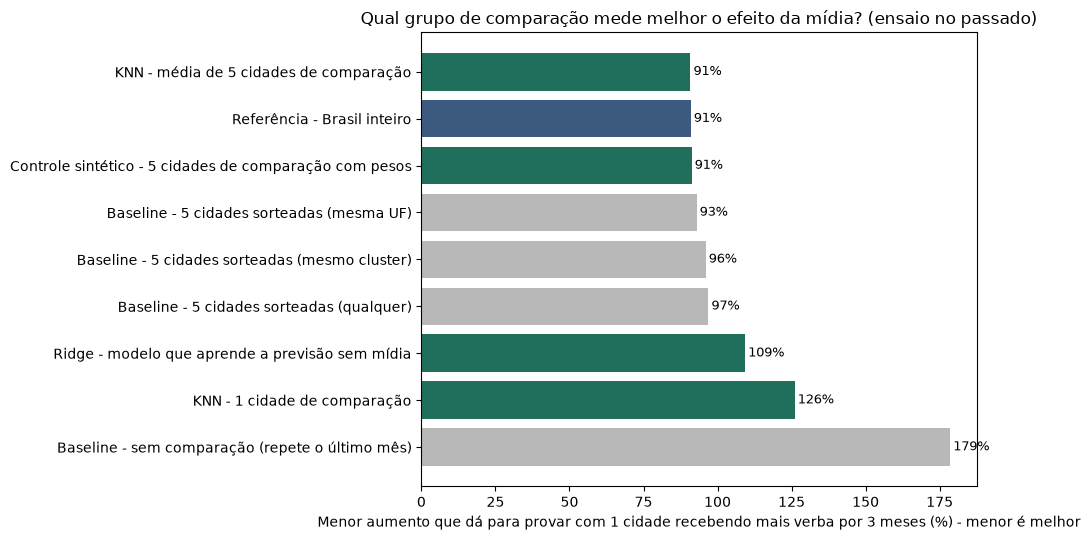

In [45]:
ordem = comparacao_metodos.sort_values("RMSE_log", ascending=False)
cores = [
    "#1f6f5c" if m.startswith(("KNN", "Controle", "Ridge")) else "#3d5a80" if m.startswith("Referência") else "#b8b8b8"
    for m in ordem["metodo"]
]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(ordem["metodo"], ordem["menor_aumento_provavel_1_cidade_pct"], color=cores)
for y_pos, valor in enumerate(ordem["menor_aumento_provavel_1_cidade_pct"]):
    ax.text(valor + 1, y_pos, f"{valor:.0f}%", va="center", fontsize=9)
ax.set_xlabel(f"Menor aumento que dá para provar com 1 cidade recebendo mais verba por {MESES_TESTE} meses (%) - menor é melhor")
ax.set_title("Qual grupo de comparação mede melhor o efeito da mídia? (ensaio no passado)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "teste_geografico_comparacao_metodos.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico: desenho do teste (quantas cidades x quanto tempo)

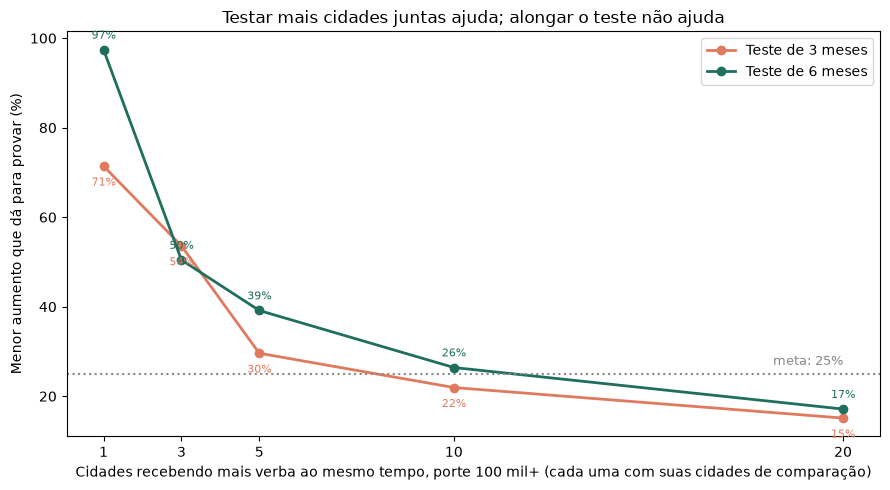

In [46]:
fig, ax = plt.subplots(figsize=(9, 5))
for meses_teste, cor, deslocamento in [(3, "#e07a5f", -14), (6, "#1f6f5c", 8)]:
    parte = desenho[desenho["meses_de_teste"] == meses_teste]
    ax.plot(parte["cidades_com_mais_verba"], parte["menor_aumento_provavel_pct"], marker="o", color=cor,
            linewidth=2, label=f"Teste de {meses_teste} meses")
    for _, linha in parte.iterrows():
        ax.annotate(f"{linha['menor_aumento_provavel_pct']:.0f}%",
                    (linha["cidades_com_mais_verba"], linha["menor_aumento_provavel_pct"]),
                    xytext=(0, deslocamento), textcoords="offset points", ha="center", fontsize=8, color=cor)
ax.axhline(META_MENOR_AUMENTO, color="#888", linestyle=":")
ax.text(desenho["cidades_com_mais_verba"].max(), META_MENOR_AUMENTO + 2, f"meta: {META_MENOR_AUMENTO}%",
        color="#888", ha="right", fontsize=9)
ax.set_xticks(sorted(desenho["cidades_com_mais_verba"].unique()))
ax.set_xlabel("Cidades recebendo mais verba ao mesmo tempo, porte 100 mil+ (cada uma com suas cidades de comparação)")
ax.set_ylabel("Menor aumento que dá para provar (%)")
ax.set_title("Testar mais cidades juntas ajuda; alongar o teste não ajuda")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "teste_geografico_desenho.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico: exemplo - candidata mais precisa x suas cidades de comparação

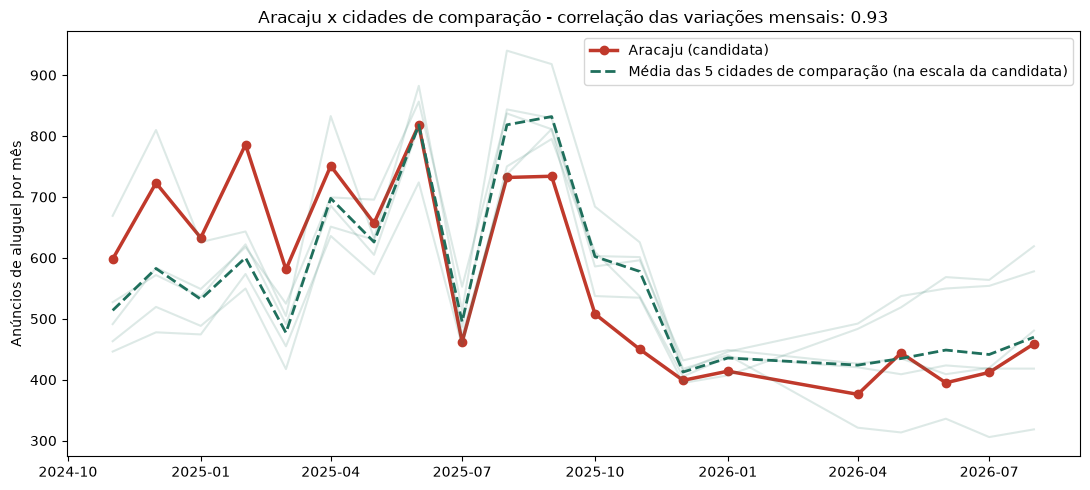

In [47]:
exemplo = grupos.iloc[0]
i, grupo = exemplo["indice"], exemplo["comparacao"]
media_comparacao = Y[grupo].mean(0)
media_alinhada = media_comparacao - media_comparacao.mean() + Y[i].mean()
datas = pd.to_datetime(meses)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(datas, np.exp(Y[i]), color="#c0392b", linewidth=2.5, marker="o", label=f"{exemplo['municipio']} (candidata)")
ax.plot(datas, np.exp(media_alinhada), color="#1f6f5c", linewidth=2, linestyle="--",
        label=f"Média das {K} cidades de comparação (na escala da candidata)")
for j in grupo:
    ax.plot(datas, np.exp(Y[j] - Y[j].mean() + Y[i].mean()), color="#1f6f5c", alpha=0.15)
ax.set_ylabel("Anúncios de aluguel por mês")
ax.set_title(f"{exemplo['municipio']} x cidades de comparação - correlação das variações mensais: "
             f"{exemplo['correlacao_variacoes']:.2f}")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "teste_geografico_exemplo.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Gráfico: precisão de cada candidata

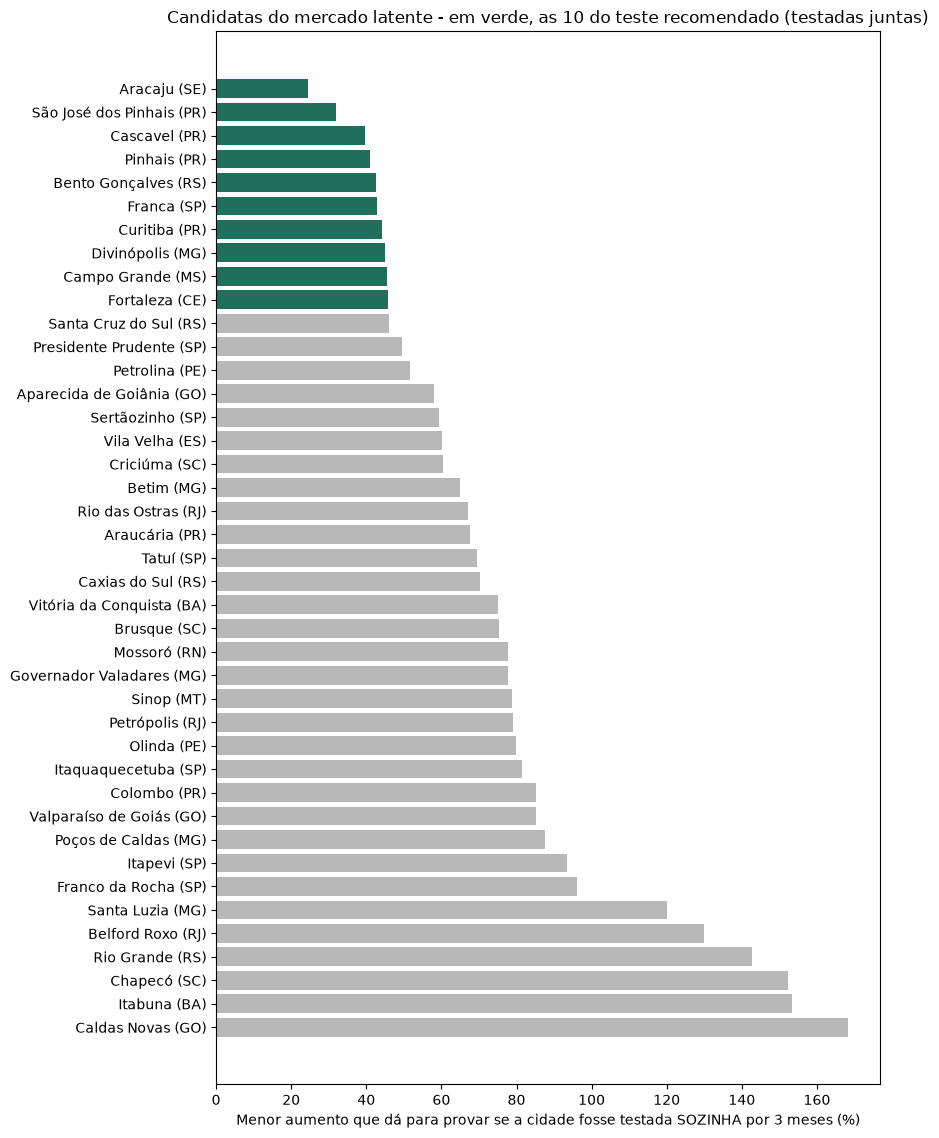

In [48]:
ordem = grupos.iloc[::-1]
cores = np.where(ordem["no_teste_recomendado"], "#1f6f5c", "#b8b8b8")

fig, ax = plt.subplots(figsize=(9, max(5, 0.28 * len(ordem))))
ax.barh(ordem["municipio"] + " (" + ordem["sigla_uf"] + ")", ordem["menor_aumento_provavel_sozinha_pct"], color=cores)
ax.set_xlabel(f"Menor aumento que dá para provar se a cidade fosse testada SOZINHA por {MESES_TESTE} meses (%)")
ax.set_title(f"Candidatas do mercado latente - em verde, as {N_RECOMENDADO} do teste recomendado (testadas juntas)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "teste_geografico_recomendado.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close()

## Conclusão

In [49]:
def aumento_de(metodo):
    return comparacao_metodos.loc[comparacao_metodos["metodo"] == metodo, "menor_aumento_provavel_1_cidade_pct"].iloc[0]


melhor_sorteio = comparacao_metodos[comparacao_metodos["metodo"].str.contains("sorteadas")].sort_values("RMSE_log").iloc[0]
d3 = desenho[desenho["meses_de_teste"] == 3].set_index("cidades_com_mais_verba")["menor_aumento_provavel_pct"]
d6 = desenho[desenho["meses_de_teste"] == 6].set_index("cidades_com_mais_verba")["menor_aumento_provavel_pct"]

print("\n============================")
print("CONCLUSÃO - TESTE GEOGRÁFICO")
print("============================")
print(
    f"1) Cidades de comparação: 5 cidades escolhidas por PCA + KNN permitem provar aumentos a partir de "
    f"{aumento_de('KNN - média de 5 cidades de comparação'):.0f}% com 1 cidade, contra "
    f"{melhor_sorteio['menor_aumento_provavel_1_cidade_pct']:.0f}% do melhor sorteio de 5 cidades, "
    f"{aumento_de('KNN - 1 cidade de comparação'):.0f}% com uma cidade de comparação só e "
    f"{aumento_de('Baseline - sem comparação (repete o último mês)'):.0f}% sem comparação. "
    "A vantagem sobre o sorteio é pequena; a grande diferença é contra usar uma cidade só ou "
    "nenhuma comparação. As 5 cidades de comparação chegam ao nível do Brasil inteiro "
    f"({aumento_de('Referência - Brasil inteiro'):.0f}%) congelando a verba de poucas cidades."
)
print(
    "2) Modelos mais complexos (controle sintético com pesos e Ridge supervisionado) não superaram "
    "a média simples das cidades de comparação: a variação por acaso que sobra é própria de cada "
    "cidade e não é previsível."
)
print(
    f"3) Desenho: testar 1 cidade por 3 meses só prova aumentos acima de {d3.loc[1]:.0f}%. "
    f"Com 10 cidades, {d3.loc[10]:.0f}%; com 20, {d3.loc[20]:.0f}%. Alongar para 6 meses NÃO ajuda "
    f"({d6.loc[10]:.0f}% com 10 cidades): a série se comporta como passeio aleatório, então o erro "
    "da previsão sem mídia cresce com o prazo. A alavanca é testar mais cidades, não esperar mais."
)
print(
    f"4) Teste recomendado: {N_RECOMENDADO} candidatas do mercado latente recebendo mais verba ao mesmo "
    f"tempo por {MESES_TESTE} meses, cada uma com {K} cidades de comparação ({cidades_congeladas} cidades "
    f"com verba congelada) -> prova aumentos a partir de {aumento_esperado:.0f}%."
)
print(
    "\nCom os dados internos da Loft, a mesma lógica vale trocando 'anúncios' por MQL ou cadastros."
)


CONCLUSÃO - TESTE GEOGRÁFICO
1) Cidades de comparação: 5 cidades escolhidas por PCA + KNN permitem provar aumentos a partir de 91% com 1 cidade, contra 93% do melhor sorteio de 5 cidades, 126% com uma cidade de comparação só e 179% sem comparação. A vantagem sobre o sorteio é pequena; a grande diferença é contra usar uma cidade só ou nenhuma comparação. As 5 cidades de comparação chegam ao nível do Brasil inteiro (91%) congelando a verba de poucas cidades.
2) Modelos mais complexos (controle sintético com pesos e Ridge supervisionado) não superaram a média simples das cidades de comparação: a variação por acaso que sobra é própria de cada cidade e não é previsível.
3) Desenho: testar 1 cidade por 3 meses só prova aumentos acima de 71%. Com 10 cidades, 22%; com 20, 15%. Alongar para 6 meses NÃO ajuda (26% com 10 cidades): a série se comporta como passeio aleatório, então o erro da previsão sem mídia cresce com o prazo. A alavanca é testar mais cidades, não esperar mais.
4) Teste recome